## Test model performance on different train-test splits by iteratively adjusting data distributions, evaluating shifts in accuracy, and ensuring stability across multiple randomized and stratified splits.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [2]:
df = pd.read_csv("heart.csv")
df = df.drop_duplicates().dropna().reset_index(drop=True)

X = df.drop("target", axis=1)
y = df["target"]

print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nTarget proportions:")
print(y.value_counts(normalize=True).round(3))

Dataset shape: (302, 14)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Target proportions:
target
1    0.543
0    0.457
Name: proportion, dtype: float64


In [3]:
random_results = []

for seed in range(5):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=seed
    )

    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    random_results.append({
        "Seed": seed,
        "Train Size": len(X_train),
        "Test Size": len(X_test),
        "Train Positive Rate": y_train.mean(),
        "Test Positive Rate": y_test.mean(),
        "Accuracy": accuracy_score(y_test, predictions)
    })

random_df = pd.DataFrame(random_results)
print(random_df.round(3))

   Seed  Train Size  Test Size  Train Positive Rate  Test Positive Rate  \
0     0         241         61                0.539               0.557   
1     1         241         61                0.548               0.525   
2     2         241         61                0.564               0.459   
3     3         241         61                0.523               0.623   
4     4         241         61                0.539               0.557   

   Accuracy  
0     0.869  
1     0.787  
2     0.852  
3     0.869  
4     0.852  


In [4]:
stratified_results = []

for seed in range(5):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=seed,
        stratify=y
    )

    model = RandomForestClassifier(random_state=42)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    stratified_results.append({
        "Seed": seed,
        "Train Positive Rate": y_train.mean(),
        "Test Positive Rate": y_test.mean(),
        "Accuracy": accuracy_score(y_test, predictions)
    })

stratified_df = pd.DataFrame(stratified_results)
print(stratified_df.round(3))

   Seed  Train Positive Rate  Test Positive Rate  Accuracy
0     0                0.544               0.541     0.869
1     1                0.544               0.541     0.836
2     2                0.544               0.541     0.770
3     3                0.544               0.541     0.787
4     4                0.544               0.541     0.852


In [5]:
ratio_results = []

for test_size in [0.3, 0.2, 0.1]:
    for seed in range(5):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=test_size,
            random_state=seed,
            stratify=y
        )

        model = RandomForestClassifier(random_state=42)
        model.fit(X_train, y_train)

        predictions = model.predict(X_test)

        ratio_results.append({
            "Test Size": test_size,
            "Seed": seed,
            "Accuracy": accuracy_score(y_test, predictions),
            "Test Rows": len(y_test),
            "Test Positive Rate": y_test.mean()
        })

ratio_df = pd.DataFrame(ratio_results)
print(ratio_df.round(3))

    Test Size  Seed  Accuracy  Test Rows  Test Positive Rate
0         0.3     0     0.813         91               0.538
1         0.3     1     0.835         91               0.538
2         0.3     2     0.824         91               0.538
3         0.3     3     0.802         91               0.538
4         0.3     4     0.857         91               0.538
5         0.2     0     0.869         61               0.541
6         0.2     1     0.836         61               0.541
7         0.2     2     0.770         61               0.541
8         0.2     3     0.787         61               0.541
9         0.2     4     0.852         61               0.541
10        0.1     0     0.839         31               0.548
11        0.1     1     0.871         31               0.548
12        0.1     2     0.742         31               0.548
13        0.1     3     0.742         31               0.548
14        0.1     4     0.839         31               0.548


In [6]:
stability = pd.DataFrame([
    {
        "Method": "Random Split 80:20",
        "Mean Accuracy": random_df["Accuracy"].mean(),
        "Std Accuracy": random_df["Accuracy"].std()
    },
    {
        "Method": "Stratified Split 80:20",
        "Mean Accuracy": stratified_df["Accuracy"].mean(),
        "Std Accuracy": stratified_df["Accuracy"].std()
    }
])

ratio_summary = ratio_df.groupby("Test Size")["Accuracy"].agg(
    ["mean", "std", "min", "max"]
).reset_index()

ratio_summary.columns = [
    "Test Size", "Mean Accuracy", "Std Accuracy", "Min Accuracy", "Max Accuracy"
]

print("Random vs Stratified:")
print(stability.round(4).to_string(index=False))

print("\nDifferent Test Ratios:")
print(ratio_summary.round(4).to_string(index=False))

Random vs Stratified:
                Method  Mean Accuracy  Std Accuracy
    Random Split 80:20         0.8459        0.0340
Stratified Split 80:20         0.8230        0.0424

Different Test Ratios:
 Test Size  Mean Accuracy  Std Accuracy  Min Accuracy  Max Accuracy
       0.1         0.8065        0.0603        0.7419        0.8710
       0.2         0.8230        0.0424        0.7705        0.8689
       0.3         0.8264        0.0211        0.8022        0.8571


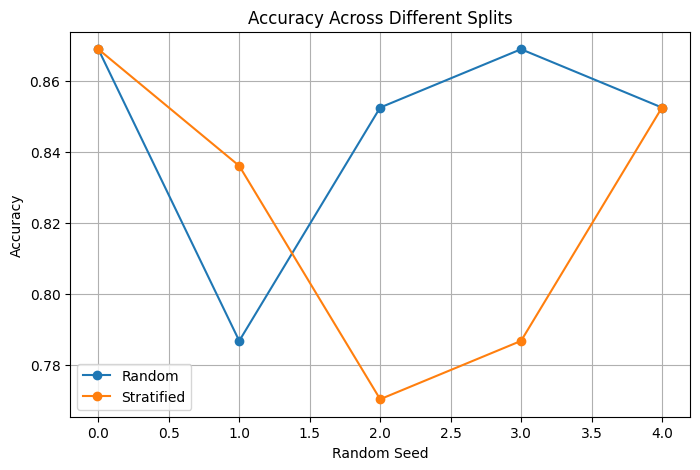

In [7]:
plt.figure(figsize=(8, 5))

plt.plot(
    random_df["Seed"],
    random_df["Accuracy"],
    marker="o",
    label="Random"
)

plt.plot(
    stratified_df["Seed"],
    stratified_df["Accuracy"],
    marker="o",
    label="Stratified"
)

plt.xlabel("Random Seed")
plt.ylabel("Accuracy")
plt.title("Accuracy Across Different Splits")
plt.legend()
plt.grid(True)
plt.show()

In [8]:
random_df.to_csv("Heart_Random_Split_Results.csv", index=False)
stratified_df.to_csv("Heart_Stratified_Split_Results.csv", index=False)
ratio_df.to_csv("Heart_Different_Ratios_Results.csv", index=False)

with open("Heart_Model_Stability_Report.txt", "w") as file:
    file.write("HEART DISEASE MODEL STABILITY REPORT\n\n")
    file.write("Random vs Stratified Splits:\n")
    file.write(stability.round(4).to_string(index=False))
    file.write("\n\nDifferent Test Ratios:\n")
    file.write(ratio_summary.round(4).to_string(index=False))
    file.write("\n\nTarget Distribution:\n")
    file.write(y.value_counts(normalize=True).round(4).to_string())
    file.write("\n\nLower standard deviation indicates less accuracy variation across tested splits.")
    file.write("\nResults reflect these splits and this model; they do not guarantee future performance.")

print("All results and report saved successfully.")

All results and report saved successfully.
